# AT 05 – Autoencoders (AE)
**Redes Neurais e Deep Learning** – Prof. Dr. Luiz Fernando Carvalho
**Aluna:** Janyne Soares da Silva

Este notebook contém:
1. Respostas dos exercícios teóricos;
2. Exercício prático: pré-treinamento de um classificador de imagens (MNIST) com um **Denoising Autoencoder (DAE)**, comparando a DNN **com** e **sem** pré-treinamento quando apenas **500 imagens rotuladas** estão disponíveis.


# 1. Exercícios teóricos

### Exercício 1. Quais são as principais tarefas em que os diferentes tipos de Autoencoders (AEs) podem ser aplicados?
Redução de dimensionalidade e visualização, extração de características (pré-treinamento não supervisionado), remoção de ruído (*Denoising AE*), detecção de anomalias pelo erro de reconstrução, compressão de dados e geração de novos dados (*Variational AE*).

### Exercício 2. Suponhamos que você queira treinar um classificador, mas tenha acesso a um dataset com uma grande quantidade de dados não rotulados e apenas algumas centenas de exemplos rotulados. Como os Autoencoders podem ajudar? Como você procederia?
O AE aprende boas representações usando os dados não rotulados, já que a reconstrução não precisa de rótulos. Eu treinaria um AE com todos os dados, descartaria o decoder e reaproveitaria o encoder como base do classificador, adicionando uma camada *softmax*. Depois treinaria com os poucos exemplos rotulados, primeiro com o encoder congelado e, se possível, fazendo *fine-tuning*. Isso reduz o *overfitting*.

### Exercício 3. Se um Autoencoder reconstrói perfeitamente um conjunto de entradas, ele é necessariamente um bom AE? Como você pode avaliar o desempenho de um AE?
Não. Ele pode apenas ter aprendido a função identidade, copiando a entrada sem extrair padrões úteis. A avaliação pode ser feita pelo erro de reconstrução em dados de teste não vistos, pela inspeção visual das reconstruções e pelo desempenho na tarefa final (por exemplo, a acurácia do classificador que usa o encoder).

### Exercício 4. O que são AEs subcompletos e sobrecompletos? Qual é o risco de um AE excessivamente subcompleto? E quais são os riscos de se ter um AE sobrecompleto?
No **subcompleto**, a camada de *codings* é menor que a entrada; no **sobrecompleto**, é igual ou maior. Um AE excessivamente subcompleto comprime demais, perde informação e não consegue reconstruir a entrada (*underfitting*). Um sobrecompleto pode copiar a entrada sem aprender padrões úteis (*overfitting*), por isso exige restrições como esparsidade, ruído ou regularização.

### Exercício 5. Como se "amarram" os pesos em um Stacked Autoencoder (SAE)? Quais são os motivos para se adotar essa abordagem?
Os pesos de cada camada do decoder são definidos como a transposta dos pesos da camada correspondente do encoder ($W_{N-L+1} = W_L^{T}$); só os *biases* do decoder são treinados separadamente. Isso reduz pela metade o número de pesos, acelera o treinamento e diminui o risco de *overfitting*.

# 2. Exercício prático – DAE para pré-treinar um classificador (MNIST)

**Escolhas de implementação:**
| Item | Escolha | Justificativa |
|---|---|---|
| Dados | MNIST do Keras (60.000 treino / 10.000 teste), pixels em [0, 1] | Divisão oficial já pronta |
| Ruído | Gaussiano (σ = 0,3), recortado em [0, 1] | Forma clássica de corromper a entrada de um DAE |
| DAE | Densa: 784 → 256 → **128** → 256 → 784 (ReLU; saída sigmoide) | AE subcompleto simples; encoder fácil de reaproveitar |
| Perda do DAE | Entropia cruzada binária, Adam | Pixels em [0, 1] |
| Classificador | Encoder (784 → 256 → 128) + Dense(10, softmax) | Mesma arquitetura em todos os cenários, comparação justa |
| Treino do classificador | 500 imagens aleatórias (80% treino / 20% validação), *early stopping* | Simula poucos dados rotulados |
| Métricas | Acurácia, F1-macro e matriz de confusão no teste (10.000) | Padrão para classificação multiclasse balanceada |
| Repetições | 5 sorteios diferentes das 500 imagens | Evita conclusões baseadas em um único sorteio |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


## 2.1 Carregando e dividindo o dataset

In [2]:
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

# normalizando os pixels para [0, 1]
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

print("Treino:", X_train.shape, "| Teste:", X_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Treino: (60000, 28, 28) | Teste: (10000, 28, 28)


## 2.2 Adicionando ruído (entrada do DAE)

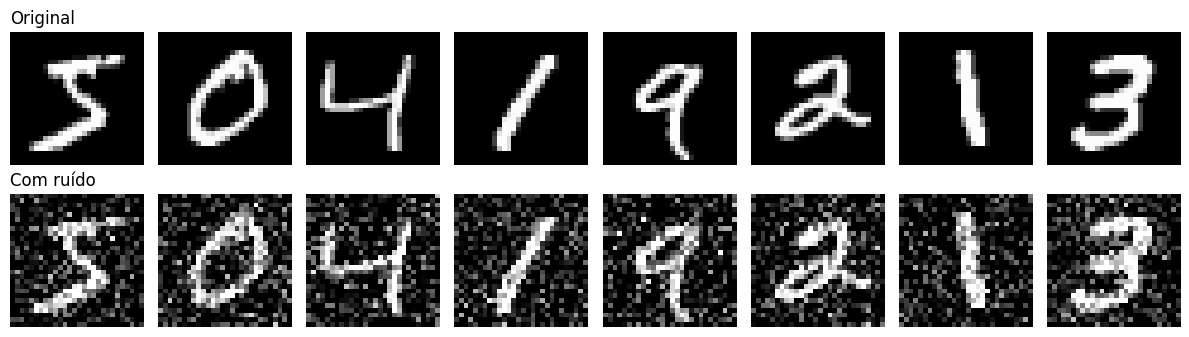

In [3]:
NOISE = 0.3

def add_noise(X, sigma=NOISE, seed=SEED):
    rng = np.random.default_rng(seed)
    return np.clip(X + sigma * rng.normal(size=X.shape), 0.0, 1.0).astype("float32")

X_train_noisy = add_noise(X_train, seed=1)
X_test_noisy = add_noise(X_test, seed=2)

fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for i in range(8):
    axes[0, i].imshow(X_train[i], cmap="gray"); axes[0, i].axis("off")
    axes[1, i].imshow(X_train_noisy[i], cmap="gray"); axes[1, i].axis("off")
axes[0, 0].set_title("Original", loc="left"); axes[1, 0].set_title("Com ruído", loc="left")
plt.tight_layout(); plt.show()

## 2.3 Construindo e treinando o DAE com todo o conjunto de treinamento

In [4]:
encoder = keras.Sequential([
    keras.Input(shape=(28, 28)),
    keras.layers.Flatten(),
    keras.layers.Dense(256, activation="relu"),
    keras.layers.Dense(128, activation="relu"),   # codings
], name="encoder")

decoder = keras.Sequential([
    keras.Input(shape=(128,)),
    keras.layers.Dense(256, activation="relu"),
    keras.layers.Dense(28 * 28, activation="sigmoid"),
    keras.layers.Reshape((28, 28)),
], name="decoder")

dae = keras.Sequential([encoder, decoder], name="dae")
dae.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy")
dae.summary()

hist_dae = dae.fit(
    X_train_noisy, X_train,           # entrada com ruído -> alvo limpo
    epochs=20, batch_size=256,
    validation_data=(X_test_noisy, X_test),
    callbacks=[keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)],
    verbose=2,
)

Model: "dae"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder (Sequential)            │ (None, 128)            │       233,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (Sequential)            │ (None, 28, 28)         │       234,512 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 468,368 (1.79 MB)

 Trainable params: 468,368 (1.79 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
235/235 - 6s - 27ms/step - loss: 0.2124 - val_loss: 0.1400
Epoch 2/20
235/235 - 1s - 4ms/step - loss: 0.1257 - val_loss: 0.1147
Epoch 3/20
235/235 - 1s - 5ms/step - loss: 0.1107 - val_loss: 0.1061
Epoch 4/20
235/235 - 1s - 6ms/step - loss: 0.1042 - val_loss: 0.1016
Epoch 5/20
235/235 - 1s - 4ms/step - loss: 0.1004 - val_loss: 0.0983
Epoch 6/20
235/235 - 1s - 4ms/step - loss: 0.0977 - val_loss: 0.0961
Epoch 7/20
235/235 - 1s - 4ms/step - loss: 0.0956 - val_loss: 0.0943
Epoch 8/20
235/235 - 1s - 4ms/step - loss: 0.0940 - val_loss: 0.0929
Epoch 9/20
235/235 - 1s - 4ms/step - loss: 0.0927 - val_loss: 0.0918
Epoch 10/20
235/235 - 1s - 4ms/step - loss: 0.0917 - val_loss: 0.0911
Epoch 11/20
235/235 - 1s - 4ms/step - loss: 0.0909 - val_loss: 0.0904
Epoch 12/20
235/235 - 1s - 4ms/step - loss: 0.0901 - val_loss: 0.0899
Epoch 13/20
235/235 - 1s - 5ms/step - loss: 0.0896 - val_loss: 0.0894
Epoch 14/20
235/235 - 1s - 4ms/step - loss: 0.0891 - val_loss: 0.0889
Epoch 15/20
235/235 - 1s - 5

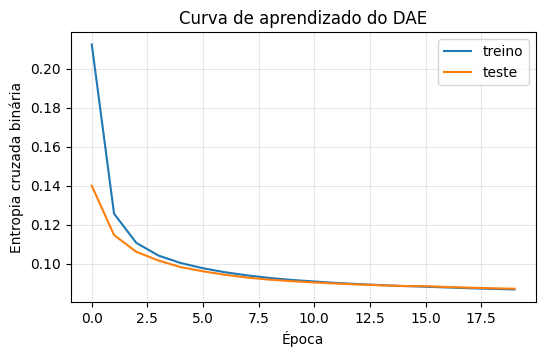

In [5]:
plt.figure(figsize=(6, 3.5))
plt.plot(hist_dae.history["loss"], label="treino")
plt.plot(hist_dae.history["val_loss"], label="teste")
plt.xlabel("Época"); plt.ylabel("Entropia cruzada binária"); plt.title("Curva de aprendizado do DAE")
plt.legend(); plt.grid(alpha=0.3); plt.show()

## 2.4 Verificando se as imagens são razoavelmente reconstruídas

MSE (imagem com ruído vs original):    0.0467
MSE (reconstrução do DAE vs original): 0.0082


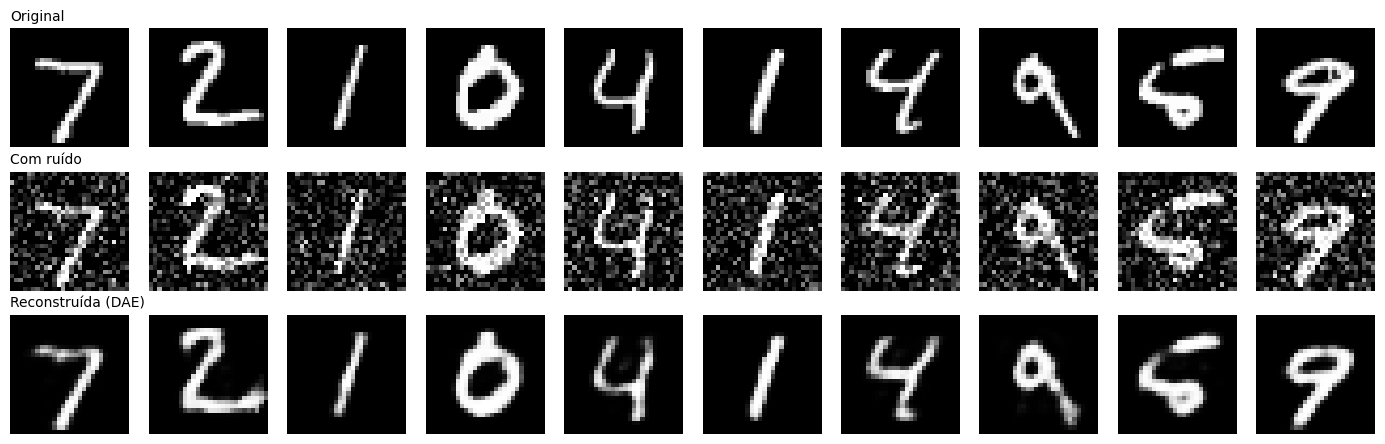

In [6]:
X_rec = dae.predict(X_test_noisy, verbose=0)

mse_noisy = np.mean((X_test_noisy - X_test) ** 2)
mse_rec = np.mean((X_rec - X_test) ** 2)
print(f"MSE (imagem com ruído vs original):    {mse_noisy:.4f}")
print(f"MSE (reconstrução do DAE vs original): {mse_rec:.4f}")

n = 10
fig, axes = plt.subplots(3, n, figsize=(14, 4.5))
for i in range(n):
    for r, img in enumerate([X_test[i], X_test_noisy[i], X_rec[i]]):
        axes[r, i].imshow(img, cmap="gray"); axes[r, i].axis("off")
for r, t in enumerate(["Original", "Com ruído", "Reconstruída (DAE)"]):
    axes[r, 0].set_title(t, loc="left", fontsize=10)
plt.tight_layout(); plt.show()

## 2.5 Criando a DNN reutilizando os pesos do DAE

Três modelos com **a mesma arquitetura** (encoder 784 → 256 → 128 + softmax de 10 classes):
- **Sem pré-treinamento:** pesos inicializados aleatoriamente;
- **DAE congelado:** pesos do encoder do DAE reaproveitados e congelados (treina só a camada de saída);
- **DAE + fine-tuning:** pesos do encoder do DAE reaproveitados e treinados junto com a saída.

In [7]:
def build_classifier(pretrained=False, trainable=True):
    enc = keras.models.clone_model(encoder)          # mesma arquitetura, pesos novos
    if pretrained:
        enc.set_weights(encoder.get_weights())       # reaproveita os pesos do DAE
    enc.trainable = trainable
    model = keras.Sequential([keras.Input(shape=(28, 28)), enc,
                              keras.layers.Dense(10, activation="softmax")])
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

CENARIOS = {
    "Sem pré-treinamento": dict(pretrained=False, trainable=True),
    "DAE congelado":       dict(pretrained=True,  trainable=False),
    "DAE + fine-tuning":   dict(pretrained=True,  trainable=True),
}

## 2.6 Treinando com apenas 500 imagens aleatórias e avaliando no teste

In [8]:
N_LABELED = 500
N_REPS = 5
resultados = {nome: {"acc": [], "f1": []} for nome in CENARIOS}
modelos_ultima_rep, historicos_ultima_rep = {}, {}

for rep in range(N_REPS):
    rng = np.random.default_rng(100 + rep)
    idx = rng.choice(len(X_train), size=N_LABELED, replace=False)
    X_small, y_small = X_train[idx], y_train[idx]

    for nome, cfg in CENARIOS.items():
        tf.random.set_seed(100 + rep)
        model = build_classifier(**cfg)
        hist = model.fit(
            X_small, y_small,
            epochs=200, batch_size=32, validation_split=0.2,
            callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=15,
                                                     restore_best_weights=True)],
            verbose=0,
        )
        y_pred = model.predict(X_test, verbose=0).argmax(axis=1)
        acc = accuracy_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred, average="macro")
        resultados[nome]["acc"].append(acc)
        resultados[nome]["f1"].append(f1)
        modelos_ultima_rep[nome] = model
        historicos_ultima_rep[nome] = hist
        print(f"Repetição {rep + 1} | {nome:<20} | acurácia = {acc:.4f} | F1-macro = {f1:.4f}")

Repetição 1 | Sem pré-treinamento  | acurácia = 0.8770 | F1-macro = 0.8759
Repetição 1 | DAE congelado        | acurácia = 0.8599 | F1-macro = 0.8583
Repetição 1 | DAE + fine-tuning    | acurácia = 0.8693 | F1-macro = 0.8676
Repetição 2 | Sem pré-treinamento  | acurácia = 0.8640 | F1-macro = 0.8612
Repetição 2 | DAE congelado        | acurácia = 0.8223 | F1-macro = 0.8188
Repetição 2 | DAE + fine-tuning    | acurácia = 0.8365 | F1-macro = 0.8340
Repetição 3 | Sem pré-treinamento  | acurácia = 0.8569 | F1-macro = 0.8549
Repetição 3 | DAE congelado        | acurácia = 0.8208 | F1-macro = 0.8182
Repetição 3 | DAE + fine-tuning    | acurácia = 0.8405 | F1-macro = 0.8380
Repetição 4 | Sem pré-treinamento  | acurácia = 0.8591 | F1-macro = 0.8569
Repetição 4 | DAE congelado        | acurácia = 0.8413 | F1-macro = 0.8392
Repetição 4 | DAE + fine-tuning    | acurácia = 0.8494 | F1-macro = 0.8464
Repetição 5 | Sem pré-treinamento  | acurácia = 0.8592 | F1-macro = 0.8554
Repetição 5 | DAE congela

## 2.7 Resultados

,Acurácia (média),Acurácia (desvio),F1-macro (média),F1-macro (desvio)
Sem pré-treinamento,0.8632,0.0073,0.8609,0.0078
DAE congelado,0.8354,0.0143,0.8325,0.0150
DAE + fine-tuning,0.8496,0.0114,0.8468,0.0116


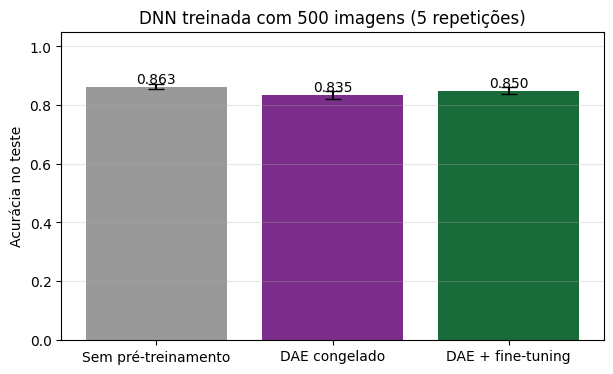

In [9]:
tabela = pd.DataFrame({
    nome: {
        "Acurácia (média)": np.mean(r["acc"]),
        "Acurácia (desvio)": np.std(r["acc"]),
        "F1-macro (média)": np.mean(r["f1"]),
        "F1-macro (desvio)": np.std(r["f1"]),
    } for nome, r in resultados.items()
}).T.round(4)
display(tabela)

nomes = list(resultados)
medias = [np.mean(resultados[n]["acc"]) for n in nomes]
desvios = [np.std(resultados[n]["acc"]) for n in nomes]
plt.figure(figsize=(7, 4))
bars = plt.bar(nomes, medias, yerr=desvios, capsize=6, color=["#999999", "#7b2d8b", "#1a6b3a"])
for b, m in zip(bars, medias):
    plt.text(b.get_x() + b.get_width() / 2, m + 0.01, f"{m:.3f}", ha="center")
plt.ylim(0, 1.05); plt.ylabel("Acurácia no teste")
plt.title(f"DNN treinada com {N_LABELED} imagens ({N_REPS} repetições)")
plt.grid(axis="y", alpha=0.3); plt.show()

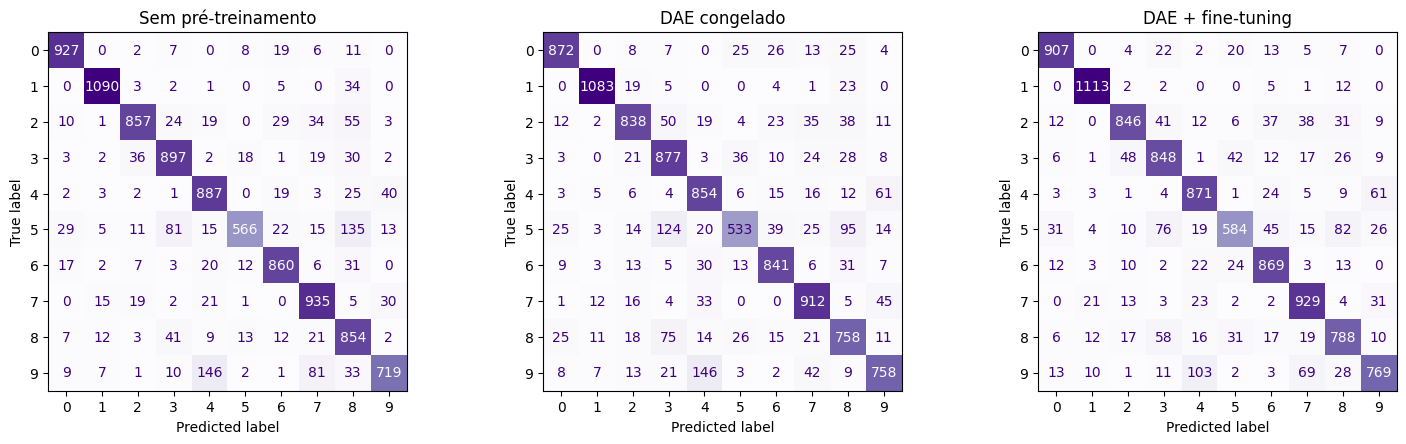

===== Sem pré-treinamento =====
              precision    recall  f1-score   support

           0     0.9233    0.9459    0.9345       980
           1     0.9587    0.9604    0.9595      1135
           2     0.9107    0.8304    0.8687      1032
           3     0.8399    0.8881    0.8633      1010
           4     0.7920    0.9033    0.8440       982
           5     0.9129    0.6345    0.7487       892
           6     0.8884    0.8977    0.8930       958
           7     0.8348    0.9095    0.8706      1028
           8     0.7040    0.8768    0.7810       974
           9     0.8888    0.7126    0.7910      1009

    accuracy                         0.8592     10000
   macro avg     0.8654    0.8559    0.8554     10000
weighted avg     0.8665    0.8592    0.8579     10000

===== DAE congelado =====
              precision    recall  f1-score   support

           0     0.9102    0.8898    0.8999       980
           1     0.9618    0.9542    0.9580      1135
           2     0.8

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (nome, model) in zip(axes, modelos_ultima_rep.items()):
    y_pred = model.predict(X_test, verbose=0).argmax(axis=1)
    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred)).plot(ax=ax, colorbar=False, cmap="Purples")
    ax.set_title(nome)
plt.tight_layout(); plt.show()

for nome, model in modelos_ultima_rep.items():
    y_pred = model.predict(X_test, verbose=0).argmax(axis=1)
    print(f"===== {nome} =====")
    print(classification_report(y_test, y_pred, digits=4, zero_division=0))

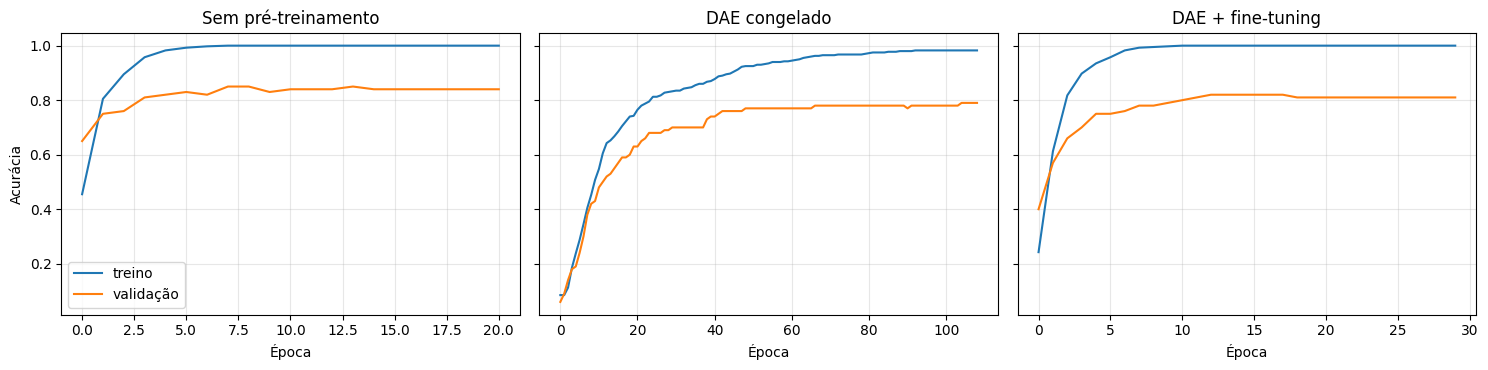

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, (nome, h) in zip(axes, historicos_ultima_rep.items()):
    ax.plot(h.history["accuracy"], label="treino")
    ax.plot(h.history["val_accuracy"], label="validação")
    ax.set_title(nome); ax.set_xlabel("Época"); ax.grid(alpha=0.3)
axes[0].set_ylabel("Acurácia"); axes[0].legend()
plt.tight_layout(); plt.show()

# 3. Discussão crítica

**A DNN tem desempenho melhor com ou sem o pré-treinamento via DAE?**
Com apenas 500 imagens rotuladas, a DNN **sem pré-treinamento** obteve acurácia média de **86,32%** (± 0,73) no teste, a versão com o **encoder do DAE congelado** obteve **83,54%** (± 1,43) e a versão **DAE + fine-tuning** obteve **84,96%** (± 1,14).
Neste experimento, o pré-treinamento **não melhorou** o desempenho: a DNN sem pré-treinamento foi cerca de **2,8 pontos percentuais** melhor que o encoder congelado e **1,4 ponto** melhor que o fine-tuning. O F1-macro seguiu o mesmo padrão (86,09%, 83,25% e 84,68%), indicando que nenhuma classe foi ignorada.

**Por que o pré-treinamento não ajudou:**
- O MNIST é um problema relativamente simples: mesmo com 400 imagens efetivas de treino, uma MLP treinada do zero já atinge mais de 86% de acurácia, deixando pouca margem para ganho.
- O DAE aprende características otimizadas para **reconstruir** a imagem, não para **separar as classes**. Essas representações preservam detalhes de forma, mas não são necessariamente as mais discriminativas.
- O DAE foi treinado com imagens **com ruído**, enquanto o classificador recebe imagens limpas, o que gera uma pequena diferença de distribuição.
- No fine-tuning, foi usada a mesma taxa de aprendizado (1e-3) dos outros cenários, o que pode ter alterado rapidamente os pesos pré-treinados e reduzido o benefício da inicialização.

**Análise das curvas de aprendizado:** nos três cenários há *overfitting*: a acurácia de treino chega perto de 100%, enquanto a de validação estabiliza entre 80% e 85%. O modelo **congelado** treina apenas a camada de saída (~1.300 parâmetros), por isso aprende bem mais devagar (cerca de 108 épocas até o *early stopping*, contra ~20 sem pré-treinamento e ~30 no fine-tuning) e fica limitado às características do DAE. Ele também teve a maior variação entre as repetições (desvio de 1,43).

**Escolhas de implementação e limitações:**
- **Arquitetura densa** (MLP) por simplicidade e facilidade de reaproveitar camadas; um DAE **convolucional** provavelmente geraria representações melhores para imagens.
- **Ruído gaussiano σ = 0,3**: forte o bastante para obrigar o DAE a aprender estrutura, sem destruir os dígitos. Outros níveis ou ruído por máscara/*dropout* poderiam ser testados.
- **Codings de 128 dimensões** (AE subcompleto); tamanhos menores (ex.: 32) aumentariam a compressão.
- **Métricas:** acurácia e F1-macro. Como o MNIST é praticamente balanceado, as duas ficam próximas; o F1-macro garante que nenhuma classe esteja sendo ignorada.
- **Validação:** 20% das 500 imagens foram usadas para *early stopping*; o treino usou efetivamente 400 imagens.
- **Repetições:** resultados são a média de 5 sorteios das 500 imagens, pois um único sorteio pode favorecer um cenário por acaso.
- **Taxa de aprendizado** igual (1e-3) em todos os cenários, para comparação justa; no *fine-tuning*, uma taxa menor poderia preservar melhor os pesos pré-treinados.
- O conjunto de **teste foi usado só para monitorar a perda de reconstrução** do DAE (sem rótulos e sem ajuste de hiperparâmetros). Num cenário mais rigoroso, usaria-se um conjunto de validação separado.

**Conclusão:** No experimento, a DNN **sem pré-treinamento** teve o melhor desempenho. Isso mostra que o pré-treinamento com autoencoders não garante ganho: depende da dificuldade do problema, da arquitetura e de como os pesos são reaproveitados. Ajustes como um DAE convolucional, uma taxa de aprendizado menor no fine-tuning ou menos exemplos rotulados (ex.: 100) poderiam tornar a vantagem do pré-treinamento mais evidente.